<a href="https://colab.research.google.com/github/wsteve16/Intro-to-Machine-Learning/blob/main/ML_HW_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

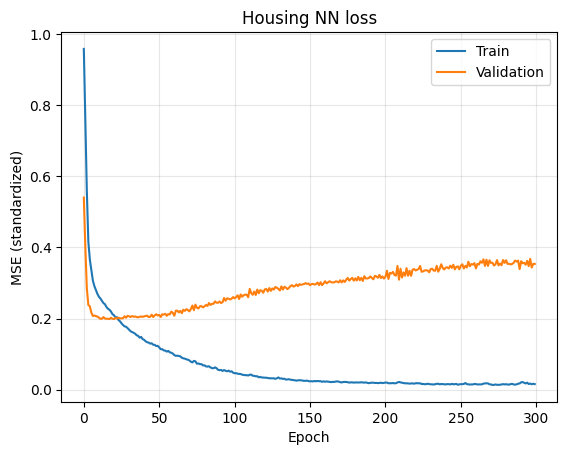

                            MSE          RMSE        R2
Neural Network     2.147695e+12  1.465502e+06  0.575098
Linear Regression  1.746012e+12  1.321367e+06  0.654568
SVR                2.075662e+12  1.440716e+06  0.589349


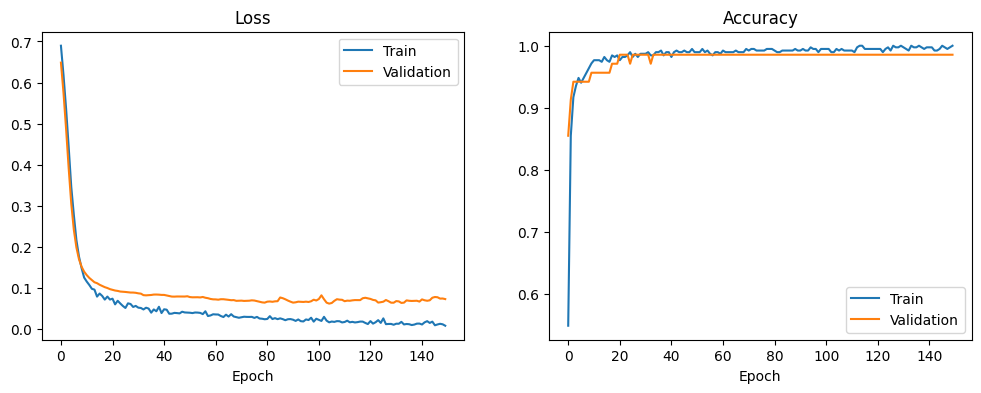

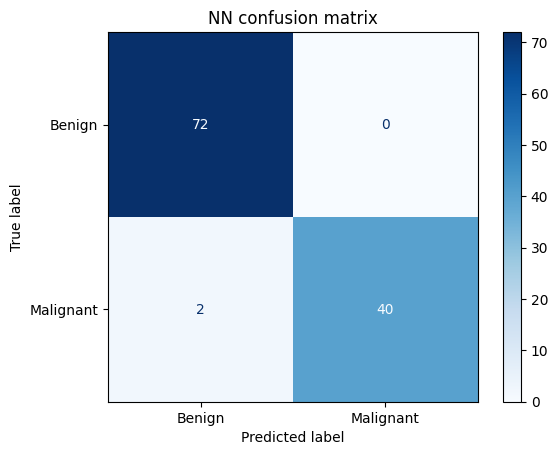

                     Accuracy  Precision    Recall        F1
Neural Network       0.982456    1.00000  0.952381  0.975610
Logistic Regression  0.973684    0.97561  0.952381  0.963855
SVM                  0.973684    0.97561  0.952381  0.963855


In [1]:
# Will Stevens
#Intro to ML HW 6
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.svm import SVR, SVC
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import (mean_squared_error, r2_score, accuracy_score,
                             precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

torch.manual_seed(42)
np.random.seed(42)

# %% [markdown]
# # Problem 1: Housing

# %%
# Load data (edit the filename and target column to match HW2)
df = pd.read_csv("Housing.csv")
df = pd.get_dummies(df, drop_first=True, dtype=float)
X = df.drop(columns=["price"]).values
y = df["price"].values.reshape(-1, 1)

# 80/20 split, then a small validation set from the training data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.15, random_state=42)

# Standardize using training data only
xs, ys = StandardScaler().fit(X_tr), StandardScaler().fit(y_tr)
X_tr_s, X_val_s, X_test_s = xs.transform(X_tr), xs.transform(X_val), xs.transform(X_test)
y_tr_s, y_val_s = ys.transform(y_tr), ys.transform(y_val)

to_t = lambda a: torch.tensor(a, dtype=torch.float32)
loader = DataLoader(TensorDataset(to_t(X_tr_s), to_t(y_tr_s)), batch_size=32, shuffle=True)

# %%
# 1.a Neural network
model = nn.Sequential(
    nn.Linear(X.shape[1], 64), nn.ReLU(),
    nn.Linear(64, 32), nn.ReLU(),
    nn.Linear(32, 1),
)
loss_fn = nn.MSELoss()
opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

train_losses, val_losses = [], []
for epoch in range(300):
    model.train()
    total = 0
    for xb, yb in loader:
        opt.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        opt.step()
        total += loss.item() * len(xb)
    train_losses.append(total / len(X_tr_s))

    model.eval()
    with torch.no_grad():
        val_losses.append(loss_fn(model(to_t(X_val_s)), to_t(y_val_s)).item())

plt.plot(train_losses, label="Train")
plt.plot(val_losses, label="Validation")
plt.xlabel("Epoch"); plt.ylabel("MSE (standardized)"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Housing NN loss")
plt.show()

model.eval()
with torch.no_grad():
    nn_pred = ys.inverse_transform(model(to_t(X_test_s)).numpy())

def reg_scores(true, pred):
    mse = mean_squared_error(true, pred)
    return [mse, np.sqrt(mse), r2_score(true, pred)]

# %%
# 1.b Compare with Linear Regression and SVR
lin = LinearRegression().fit(X_tr_s, y_tr)
svr = SVR(kernel="rbf", C=1).fit(X_tr_s, y_tr_s.ravel())
svr_pred = ys.inverse_transform(svr.predict(X_test_s).reshape(-1, 1))

results = pd.DataFrame(
    [reg_scores(y_test, nn_pred),
     reg_scores(y_test, lin.predict(X_test_s)),
     reg_scores(y_test, svr_pred)],
    index=["Neural Network", "Linear Regression", "SVR"],
    columns=["MSE", "RMSE", "R2"])
print(results)

# %% [markdown]
# # Problem 2: Breast Cancer

# %%
data = load_breast_cancer()
X = data.data
y = (1 - data.target).reshape(-1, 1)   # 1 = malignant, 0 = benign

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.15, random_state=42, stratify=y_train)

sc = StandardScaler().fit(X_tr)
X_tr_s, X_val_s, X_test_s = sc.transform(X_tr), sc.transform(X_val), sc.transform(X_test)

loader = DataLoader(TensorDataset(to_t(X_tr_s), to_t(y_tr)), batch_size=32, shuffle=True)

# %%
# 2.a Neural network
model = nn.Sequential(
    nn.Linear(30, 32), nn.ReLU(), nn.Dropout(0.2),
    nn.Linear(32, 16), nn.ReLU(), nn.Dropout(0.2),
    nn.Linear(16, 1),
)
loss_fn = nn.BCEWithLogitsLoss()
opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-3)

train_losses, val_losses, train_accs, val_accs = [], [], [], []
for epoch in range(150):
    model.train()
    total, correct = 0, 0
    for xb, yb in loader:
        opt.zero_grad()
        out = model(xb)
        loss = loss_fn(out, yb)
        loss.backward()
        opt.step()
        total += loss.item() * len(xb)
        correct += ((out > 0).float() == yb).sum().item()
    train_losses.append(total / len(X_tr_s))
    train_accs.append(correct / len(X_tr_s))

    model.eval()
    with torch.no_grad():
        out = model(to_t(X_val_s))
        val_losses.append(loss_fn(out, to_t(y_val)).item())
        val_accs.append(((out > 0).float() == to_t(y_val)).float().mean().item())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(train_losses, label="Train"); ax[0].plot(val_losses, label="Validation")
ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(train_accs, label="Train"); ax[1].plot(val_accs, label="Validation")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.show()

model.eval()
with torch.no_grad():
    nn_pred = (model(to_t(X_test_s)) > 0).int().numpy()

ConfusionMatrixDisplay(confusion_matrix(y_test, nn_pred),
                       display_labels=["Benign", "Malignant"]).plot(cmap="Blues")
plt.title("NN confusion matrix")
plt.show()

def clf_scores(true, pred):
    return [accuracy_score(true, pred), precision_score(true, pred),
            recall_score(true, pred), f1_score(true, pred)]

# %%
# 2.b Compare with Logistic Regression and SVM
logreg = LogisticRegression(max_iter=1000).fit(X_tr_s, y_tr.ravel())
svm = SVC(kernel="rbf", C=1).fit(X_tr_s, y_tr.ravel())

results = pd.DataFrame(
    [clf_scores(y_test, nn_pred),
     clf_scores(y_test, logreg.predict(X_test_s)),
     clf_scores(y_test, svm.predict(X_test_s))],
    index=["Neural Network", "Logistic Regression", "SVM"],
    columns=["Accuracy", "Precision", "Recall", "F1"])
print(results)